# Applied Data Augmentation CNN (Task 4)

### Import Libraries

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

### Prepare Dataset

1. Load Dataset

In [2]:
# Train
print("Train Dataset:")
train_dataset = tf.keras.utils.image_dataset_from_directory(
    "seg_train/seg_train",
    image_size=(150, 150),
    validation_split=0.2,
    subset="training",
    seed=42
)

# Validate
print("\nValidate Dataset:")
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    "seg_train/seg_train",
    image_size=(150,150),
    batch_size=32,
    validation_split=0.2,
    subset="validation",
    seed=42
)

print("\nTest Dataset:")
# Test
test_dataset = tf.keras.utils.image_dataset_from_directory(
    "seg_test/seg_test",
    image_size=(150, 150),
    batch_size=32,
    shuffle=False
)

class_names = train_dataset.class_names
num_classes = len(class_names)

Train Dataset:
Found 14034 files belonging to 6 classes.
Using 11228 files for training.

Validate Dataset:
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.

Test Dataset:
Found 3000 files belonging to 6 classes.


2. Normalization

Added Data Augmentation:
- **RandomFlip:** Helps the model recognize an object even when its position/orientation is reversed.
- **RandomRotation:** Makes the model less sensitive to small changes in the camera angle.
- **RandomZoom:** Helps the model recognize objects whether they appear closer or farther away.
- **RandomBrightness:** Helps the model handle images taken under different lighting conditions.

In [3]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomBrightness(0.1)
])

normalization_layer = tf.keras.layers.Rescaling(1./255)

def augment_and_normalize(x, y):
    x = data_augmentation(x, training=True)
    x = normalization_layer(x)
    return x, y

def normalize_data(x, y):
    x = normalization_layer(x)
    return x, y



train_dataset = train_dataset.map(augment_and_normalize)

validation_dataset = validation_dataset.map(normalize_data)

test_dataset = test_dataset.map(normalize_data)

3. Example Images

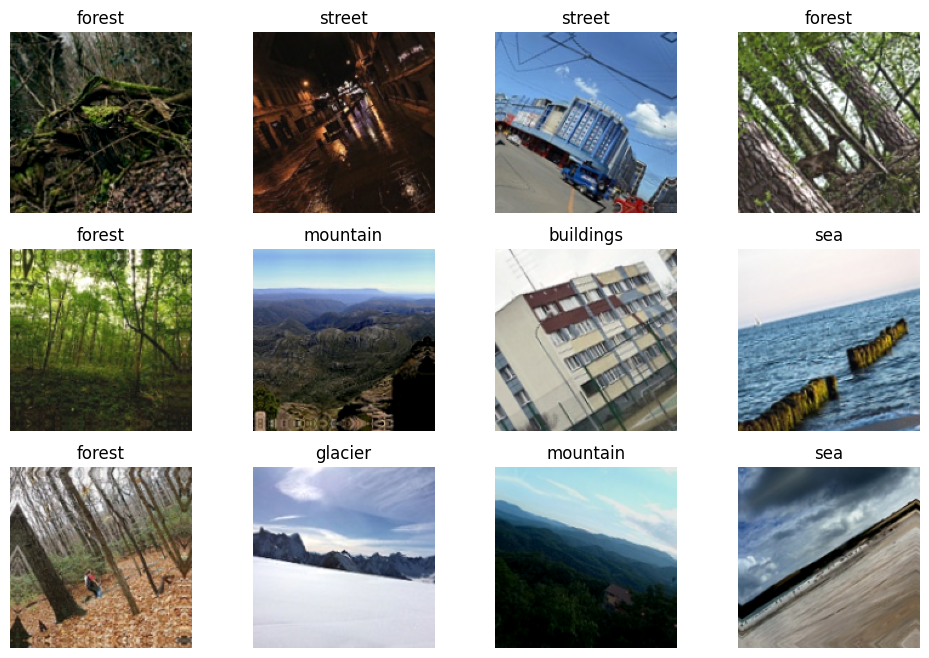

In [4]:
plt.figure(figsize=(12, 8))

for images, labels in train_dataset.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)

        plt.imshow(images[i])
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.show()

### CNN model

1. Build a model (Using the modified model from task 3)

In [5]:
model = Sequential([

    Conv2D(32, (3, 3), activation="relu", input_shape=(150, 150, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dense(num_classes, activation="softmax")
    
])

c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2. Compile and Train
- Use **Sparse Categorical Cross Entropy** if the labels look like 3,6,2,...
- Use **Categorical Cross Entropy** if the labels look like [0,1,0,...] [0,...,1,0]

In [6]:
# Compile
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10


c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


351/351 ━━━━━━━━━━━━━━━━━━━━ 60s 169ms/step - accuracy: 0.5485 - loss: 1.1437 - val_accuracy: 0.5852 - val_loss: 1.1146
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 59s 169ms/step - accuracy: 0.6672 - loss: 0.8861 - val_accuracy: 0.7206 - val_loss: 0.7550
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 59s 167ms/step - accuracy: 0.7165 - loss: 0.7747 - val_accuracy: 0.7452 - val_loss: 0.6819
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 59s 168ms/step - accuracy: 0.7447 - loss: 0.6911 - val_accuracy: 0.7434 - val_loss: 0.6784
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 59s 168ms/step - accuracy: 0.7639 - loss: 0.6525 - val_accuracy: 0.7748 - val_loss: 0.6475
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 59s 169ms/step - accuracy: 0.7777 - loss: 0.6048 - val_accuracy: 0.7865 - val_loss: 0.5951
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 60s 171ms/step - accuracy: 0.7873 - loss: 0.5749 - val_accuracy: 0.7395 - val_loss: 0.7108
Epoch 8/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 59s 168ms/step - accuracy: 0.7996 - loss: 0.5516 - val

3. Evaluate

In [7]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.8100 - loss: 0.5476
Test Accuracy: 81.00%


4. Save

In [8]:
model.save("CNN_Data_Augmented.keras")